# Traffic Signal Violation Detection & e-Challan System (Student Edition)

## What are we building?
An **AI Traffic Police Assistant** that looks at a single traffic-camera photo and
automatically:
1. Finds every vehicle (car, motorcycle, bus, truck)
2. Checks if a vehicle **crossed the stop line**
3. **Reads the number plate** of any violator
4. Prints a **traffic challan** (fine ticket) — just like a real one

## How this notebook is organized
We build everything up **one small step at a time** on a single photo, so you can see exactly
what's happening inside each piece, before putting it all together into one final cell.

```
Photo
     |
YOLOv8 Vehicle Detector  ---->  draws a box around every car/bike/bus/truck
     |
Virtual Stop Line  ---->  has this vehicle crossed the line?  --no--> ignore
     |
    yes
     |
YOLOv8 License Plate Detector  ---->  finds the plate region inside the vehicle's box
     |
EasyOCR (sharpened + auto-corrected)  ---->  reads the plate text (e.g. "KA03KA2878")
     |
e-Challan                       ---->  prints a traffic fine ticket
```

## Step 1: Install and Import the Libraries

- **`ultralytics`** → gives us YOLOv8, used **twice**: once for vehicles, once for plates.
- **`easyocr`** → reads the actual characters out of a cropped plate photo.
- **`opencv-python`** (`cv2`) → opens images and draws boxes/lines on them.


In [23]:
# Install required libraries (only needs to run once per environment)
# %pip install -q ultralytics huggingface_hub easyocr opencv-python pandas

import os
import re
import cv2
import random
import sqlite3
import requests
import numpy as np  
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from IPython.display import display, HTML

from ultralytics import YOLO
from huggingface_hub import hf_hub_download
import easyocr

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Load Our Photo

We don't have a live traffic camera in this environment, so we work with a single real
snapshot (`sample_violation_image.png`) — exactly like a zoomed-in ANPR (Automatic Number
Plate Recognition) camera would capture at a real junction.


In [ ]:
IMAGE_PATH = r"D:\Data Science_bat\DeepLearning\sample_violation_image.png"

# assert os.path.exists(IMAGE_PATH), f"Couldn't find {IMAGE_PATH} — upload it to this notebook's folder."

anpr_snapshot = cv2.imread(IMAGE_PATH)

plt.figure(figsize=(7, 5))
plt.imshow(cv2.cvtColor(anpr_snapshot, cv2.COLOR_BGR2RGB))
plt.title("Zoomed ANPR camera (snapshot)")
plt.axis('off')
plt.show()

## Step 3: Load the Vehicle Detector + Set Fine Amounts

`yolov8n.pt` is **pretrained** on millions of real photos — it already knows how to spot
`car`, `motorcycle`, `bus`, and `truck`, so we don't train anything ourselves. We also attach a
₹ fine to each vehicle type, based on Bengaluru Traffic Police's published red-light fines.


In [3]:
# Load the pretrained YOLOv8 vehicle detector
vehicle_model = YOLO("yolov8n.pt")

# COCO class id -> (readable vehicle type, fine amount in INR)
VEHICLE_FINES = {
    2: ("Car / Four-wheeler", 2000),
    3: ("Motorcycle / Two-wheeler", 1000),
    5: ("Bus / Heavy Vehicle", 5000),
    7: ("Truck / Heavy Vehicle", 5000),
}

print("Vehicle detector ready. Watching for:", [v[0] for v in VEHICLE_FINES.values()])

Vehicle detector ready. Watching for: ['Car / Four-wheeler', 'Motorcycle / Two-wheeler', 'Bus / Heavy Vehicle', 'Truck / Heavy Vehicle']


## Step 4: Load the License Plate Detector (Simplified!)

A generic vehicle detector doesn't know what a "license plate" looks like. So we use a
**second YOLOv8 model**, fine-tuned specifically to find plates.

**This is one of our simplifications:** earlier we downloaded this model fresh from the
internet every time (`hf_hub_download(...)`). Now the weights file is saved directly in the
Colab session (`/content/license_plate_detector.pt`), so we just load it straight from disk —
faster, and it still works even without internet mid-session.


In [5]:
# Download the fine-tuned license-plate weights from Hugging Face Hub
plate_weights_path = r"D:\Data Science_bat\DeepLearning\license_plate_detector.pt"

plate_model = YOLO(plate_weights_path)
print("License plate detector ready!")

License plate detector ready!


## Step 5: The Plate-Reading Toolbox

**OCR (Optical Character Recognition)** turns a *picture* of text into *actual characters*. But
a naive "crop + OCR" can get individual characters wrong — especially on small plate crops. So
we build two small helper functions:

| Function | What it does, in plain English |
|---|---|
| `correct_plate_text()` | OCR often confuses look-alike characters (`0`↔`O`, `3`↔`J`, `A`↔`4`). Since every Indian plate follows the fixed pattern `LL DD LL DDDD`, we can automatically fix characters that are the *wrong type* for their position |
| `detect_and_read_plate()` | Combines everything: find the plate → crop it → run OCR → clean up the text → auto-correct it → check whether it matches a real plate format |


In [ ]:
# EasyOCR reader (English)
ocr_reader = easyocr.Reader(['en'], gpu=False)

# General Indian number-plate pattern, e.g. KA01AB1234
INDIAN_PLATE_PATTERN = re.compile(r'^[A-Z]{2}\d{2}[A-Z]{1,2}\d{4}$')

# OCR's most common digit<->letter look-alike mix-ups
DIGIT_TO_LETTER = {'0': 'O', '1': 'I', '2': 'Z', '3': 'J', '4': 'A', '5': 'S', '6': 'G', '8': 'B'}
LETTER_TO_DIGIT = {'O': '0', 'I': '1', 'Z': '2', 'J': '3', 'A': '4', 'S': '5', 'G': '6', 'B': '8'}


def correct_plate_text(raw_text):
    # Fix OCR digit<->letter mix-ups using the KNOWN, fixed structure of an Indian plate:
    #   LL DD LL DDDD  (10 chars, 2-letter series)  or  LL DD L DDDD  (9 chars, 1-letter series)
    if len(raw_text) == 10:
        letter_positions, digit_positions = [0, 1, 4, 5], [2, 3, 6, 7, 8, 9]
    elif len(raw_text) == 9:
        letter_positions, digit_positions = [0, 1, 4], [2, 3, 5, 6, 7, 8]
    else:
        return raw_text  # unexpected length -> leave as-is (still flagged for manual review)

    chars = list(raw_text)
    for i in letter_positions:
        if chars[i].isdigit():
            chars[i] = DIGIT_TO_LETTER.get(chars[i], chars[i])
    for i in digit_positions:
        if chars[i].isalpha():
            chars[i] = LETTER_TO_DIGIT.get(chars[i], chars[i])
    return "".join(chars)


def detect_and_read_plate(vehicle_crop):
    # Given a cropped vehicle image, find + read its license plate.
    # Returns (plate_text, plate_is_valid_format, plate_crop_image)
    if vehicle_crop is None or vehicle_crop.size == 0:
        return "UNREADABLE", False, None

    results = plate_model(vehicle_crop, verbose=False)
    boxes = results[0].boxes

    if len(boxes) == 0:
        return "UNREADABLE", False, None

    # Use the plate detection with the highest confidence
    best_idx = int(boxes.conf.argmax())
    px1, py1, px2, py2 = map(int, boxes.xyxy[best_idx])
    plate_crop = vehicle_crop[max(0, py1):py2, max(0, px1):px2]

    if plate_crop.size == 0:
        return "UNREADABLE", False, None

    # Run OCR directly on the crop, restricted to letters/digits only
    ocr_result = ocr_reader.readtext(plate_crop, allowlist='ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789')
    print(raw_text)
    raw_text = "".join(text for (_, text, conf) in ocr_result if conf > 0.3)
    clean_text = re.sub(r'[^A-Z0-9]', '', raw_text.upper())

    if not clean_text:
        return "UNREADABLE", False, plate_crop

    corrected_text = correct_plate_text(clean_text)
    is_valid = bool(INDIAN_PLATE_PATTERN.match(corrected_text))
    return corrected_text, is_valid, plate_crop


print("Plate reading function ready!")

Using CPU. Note: This module is much faster with a GPU.


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompletePlate reading function ready!


c:\Users\v-maheshkur\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(


## Step 5b: Quick Test — Read the Plate from Our Zoomed ANPR Snapshot

Before trusting this pipeline further, let's sanity-check it and **look at what OCR is
actually seeing** — the detected plate crop and its final, corrected reading.


Plate read: 'KA03KA2878'  |  matches Indian format: True


c:\Users\v-maheshkur\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


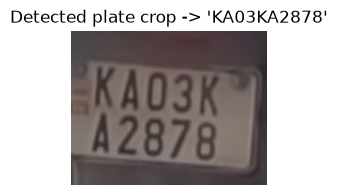

In [7]:
test_plate_text, test_plate_valid, test_plate_crop = detect_and_read_plate(anpr_snapshot)

print(f"Plate read: '{test_plate_text}'  |  matches Indian format: {test_plate_valid}")

if test_plate_crop is not None:
    plt.figure(figsize=(5, 2))
    plt.imshow(cv2.cvtColor(test_plate_crop, cv2.COLOR_BGR2RGB))
    plt.title(f"Detected plate crop -> '{test_plate_text}'")
    plt.axis('off')
    plt.show()

## Step 6: A Basic YOLO Call

Now let's slow down and rebuild these same ideas, one tiny step at a time, on our photo — this
is the best way to actually understand what's happening *inside* the bigger functions above.

Just get the model ready to run it — no helper functions hiding what's inside. We reuse the
vehicle detector we already loaded, instead of loading the same weights twice.


In [3]:
# Reuse the vehicle detector we already loaded earlier (no need to load it twice)

vehicle_model = YOLO(r"D:\Data Science_bat\DeepLearning\license_plate_detector.pt")
model = vehicle_model
print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


Run the model on one photo, and look at the **raw result object** — this is exactly what
`detect_and_read_plate()` works with internally, just without any helper functions wrapping it.


In [4]:
result = vehicle_model.predict(r"D:\Data Science_bat\DeepLearning\sample_violation_image.png")


image 1/1 D:\Data Science_bat\DeepLearning\sample_violation_image.png: 480x640 1 license_plate, 213.0ms
Speed: 14.5ms preprocess, 213.0ms inference, 27.5ms postprocess per image at shape (1, 3, 480, 640)


In [6]:
result[0]

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'license_plate'}
obb: None
orig_img: array([[[205, 212, 215],
        [205, 212, 215],
        [207, 211, 216],
        ...,
        [198, 194, 205],
        [171, 167, 178],
        [142, 141, 151]],

       [[204, 210, 215],
        [205, 211, 216],
        [205, 209, 214],
        ...,
        [203, 197, 208],
        [177, 173, 184],
        [152, 151, 161]],

       [[203, 209, 216],
        [204, 210, 215],
        [208, 212, 217],
        ...,
        [207, 201, 212],
        [180, 177, 186],
        [166, 163, 172]],

       ...,

       [[218, 217, 219],
        [218, 217, 219],
        [214, 216, 217],
        ...,
        [158, 154, 165],
        [155, 154, 164],
        [157, 156, 166]],

       [[215, 215, 215],
        [214, 214, 214],
        [214, 214, 214],
        ...,
        [157, 153, 164],
        [157, 156, 

## Pulling Numbers Out of the Result

- `cls` → which class was detected (as a number, e.g. `3.0`)
- `conf` → how confident the model is (e.g. `0.91`)


In [9]:
result[0].boxes

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0.])
conf: tensor([0.6884])
data: tensor([[1.6861e+03, 1.4935e+03, 1.8796e+03, 1.6440e+03, 6.8836e-01, 0.0000e+00]])
id: None
is_track: False
orig_shape: (1728, 2422)
shape: torch.Size([1, 6])
xywh: tensor([[1782.8408, 1568.7695,  193.5278,  150.5448]])
xywhn: tensor([[0.7361, 0.9079, 0.0799, 0.0871]])
xyxy: tensor([[1686.0769, 1493.4971, 1879.6047, 1644.0419]])
xyxyn: tensor([[0.6962, 0.8643, 0.7761, 0.9514]])

In [7]:
cls = float(result[0].boxes.cls[0])
conf = result[0].boxes.conf[0]

In [8]:
cls, conf

(0.0, tensor(0.6884))

Turn that class number into a readable name, e.g. `"motorcycle"`.

> 💡 **Fun Python fact:** `cls` is a *float* like `3.0`, but `result[0].names` is a dictionary
> with *integer* keys like `{3: "motorcycle"}`. This still works because in Python,
> `3 == 3.0` — so a dictionary happily treats them as the same key!


In [10]:
result[0].names[cls]

'license_plate'

## Looking at the Box Format

YOLO can give you a box as **(center_x, center_y, width, height)** instead of corners — this
cell just prints that raw format so you can see it.


In [22]:
len(result[0].boxes.xyxy[0])

4

## A Basic Image Display

The "hello world" of image display: load the photo with `cv2.imread` and show it with
`plt.imshow` (remembering to convert BGR → RGB, since OpenCV and Matplotlib disagree on color
order!).


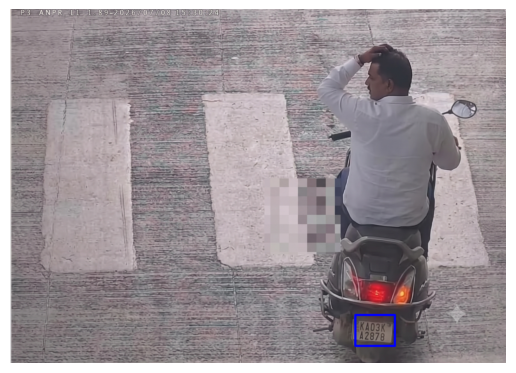

In [21]:
# matplotlib and cv2 are already imported above -- reusing them here
# Read the image file using OpenCV first
img = cv2.imread(r"D:\Data Science_bat\DeepLearning\sample_violation_image.png")

# Convert color space from BGR to RGB for correct rendering in Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
x1, y1, x2, y2 =  map(int, result[0].boxes.xyxy[0])
cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 0, 255), 10)

plt.imshow(img_rgb)
plt.draw()
plt.axis('off')
plt.show()

## Manually Converting a Box Format

A great teaching exercise: converting "center + size" into "two corners" **by hand**, which is
exactly what YOLO does internally when it gives you `.xyxy` directly. Doing it once yourself
makes the format click.


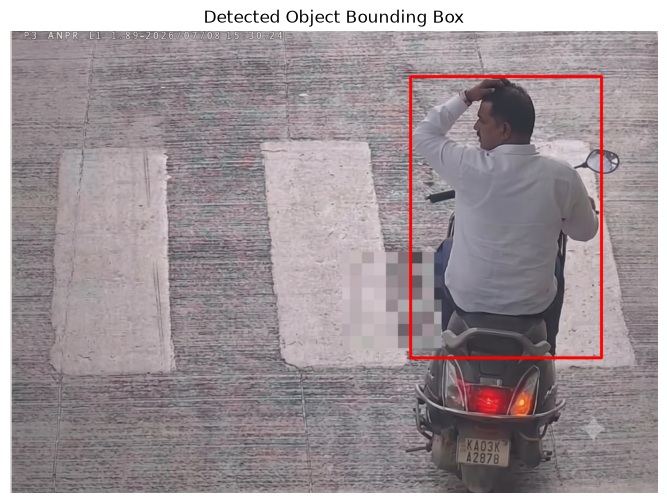

In [19]:
# Retrieve the tensor from result[0].boxes.xywh
xywh = result[0].boxes.xywh[0].cpu().numpy()
x_center, y_center, width, height = xywh

# Convert Center x, Center y, Width, Height to corner coordinates (x1, y1, x2, y2)
x1 = int(x_center - (width / 2))
y1 = int(y_center - (height / 2))
x2 = int(x_center + (width / 2))
y2 = int(y_center + (height / 2))

# Read image and draw the rectangle
img_box = cv2.imread(r"D:\Data Science_bat\DeepLearning\sample_violation_image.png")
cv2.rectangle(img_box, (x1, y1), (x2, y2), (0, 0, 255), 10)  # Green box with thickness 10

# Convert to RGB and display
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img_box, cv2.COLOR_BGR2RGB))
plt.title("Detected Object Bounding Box")
plt.axis('off')
plt.show()

## Using the Plate Model Directly (No Helper Function)

Run the plate detector by itself on the photo and look at its raw class/confidence output —
the "manual" version of what `detect_and_read_plate()` automates for you.


In [21]:

# plate_model is already loaded above -- reusing it here
plate_result = plate_model.predict(r"D:\Data Science_bat\DeepLearning\sample_violation_image.png")
cls = float(plate_result[0].boxes.cls[0])
conf = plate_result[0].boxes.conf[0]
plate_result[0].names[cls]



image 1/1 D:\Data Science_bat\DeepLearning\sample_violation_image.png: 480x640 1 license_plate, 149.3ms
Speed: 13.6ms preprocess, 149.3ms inference, 9.5ms postprocess per image at shape (1, 3, 480, 640)


'license_plate'

## Filtering by Confidence and Cropping Each Detection

Only keep detections above a confidence threshold, then crop and display each one — this is the
manual version of the plate-finding step inside `detect_and_read_plate()`.


Detected license_plate with confidence 0.69 at [1686, 1493, 1879, 1644]


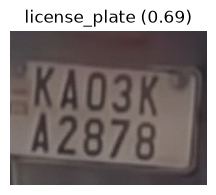

In [22]:
# Predict using the plate model
results = plate_model.predict(r"D:\Data Science_bat\DeepLearning\sample_violation_image.png", verbose=False)
boxes = results[0].boxes

# Filter detections where confidence is above a certain threshold (e.g., 0.5)
confidence_threshold = 0.5

for box in boxes:
    conf = float(box.conf[0])
    cls_id = int(box.cls[0])
    class_name = plate_model.names[cls_id]

    if conf >= confidence_threshold:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        print(f"Detected {class_name} with confidence {conf:.2f} at [{x1}, {y1}, {x2}, {y2}]")

        # Crop and display the license plate
        plate_crop = results[0].orig_img[y1:y2, x1:x2]
        plt.figure(figsize=(4, 2))
        plt.imshow(cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB))
        plt.title(f"{class_name} ({conf:.2f})")
        plt.axis('off')
        plt.show()

## Now Use the Real Function

The toolbox function from earlier (`detect_and_read_plate()`) gives you the same (better,
auto-corrected) answer in one line — bridging the "manual" and "automated" approaches.


In [23]:
# Extract plate details using the specialized function on the ANPR snapshot
plate_text, is_valid, plate_crop_img = detect_and_read_plate(anpr_snapshot)

if plate_crop_img is not None and plate_crop_img.size > 0:
    # Save the cropped license plate image to disk
    output_path = "/content/extracted_plate_crop.png"
    cv2.imwrite(output_path, plate_crop_img)
    print(f"Cropped plate image successfully saved to: {output_path}")
    print(f"Extracted License Plate Number: {plate_text}")
    print(f"Matches standard Indian format: {is_valid}")
else:
    print("Could not find or crop any license plate from the image.")

Cropped plate image successfully saved to: /content/extracted_plate_crop.png
Extracted License Plate Number: KA03KA2878
Matches standard Indian format: True


## Opening Up the OCR + Correction Step

Prints **both** the raw OCR guess and the auto-corrected version side by side — a direct, visible
demonstration of how much `correct_plate_text()` helps.


In [24]:
# Predict license plates
results = plate_model.predict(anpr_snapshot, verbose=False)
boxes = results[0].boxes
# INDIAN_PLATE_PATTERN is already defined earlier -- reusing it here

if len(boxes) > 0:
    # Get the best crop coordinates
    best_idx = int(boxes.conf.argmax())
    x1, y1, x2, y2 = map(int, boxes.xyxy[best_idx])
    plate_crop = anpr_snapshot[y1:y2, x1:x2]

    # Run EasyOCR directly on the cropped image
    ocr_results = ocr_reader.readtext(plate_crop, allowlist='ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789')
    raw_extracted_text = "".join([text for (_, text, _) in ocr_results]).upper()

    # Refine the extraction with cleanups and format correction
    clean_text = re.sub(r'[^A-Z0-9]', '', raw_extracted_text)
    refined_text = correct_plate_text(clean_text)

    print("Raw OCR Extracted:", raw_extracted_text)
    print("Refined Plate Number:", refined_text)
    print("Is Valid Format:", bool(INDIAN_PLATE_PATTERN.match(refined_text)))
else:
    print("No license plates detected to extract numbers from.")

Raw OCR Extracted: KAO3K42878
Refined Plate Number: KA03KA2878
Is Valid Format: True


## The Whole System, Shrunk Into One Cell

The capstone: this brings together everything we've built — draws a stop line, checks for
a crossing, reads the plate, and prints an HTML "TRAFFIC VIOLATION CHALLAN" with the evidence
photo, all in one cell.

> 📝 **Note:** this cell reads the plate from the **whole photo** rather than cropping to just
> the vehicle first. It still works, since the plate detector can find a plate anywhere in an
> image — just slightly less precise than cropping to the vehicle region first.


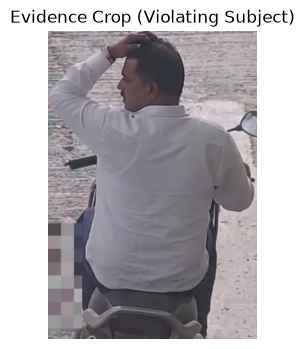

In [25]:
# --- Step 1: Define the line-crossing parameters on our ANPR Snapshot ---
img_raw = anpr_snapshot.copy()  # reuse the already-loaded snapshot instead of re-reading from disk
height, width = img_raw.shape[:2]

# Let's define a virtual horizontal stop-line at 40% height of the frame for demonstration
STOP_LINE_Y = int(height * 0.40)

# --- Step 2: Detect objects ---
vehicle_results = vehicle_model.predict(IMAGE_PATH, verbose=False)
boxes = vehicle_results[0].boxes

violation_detected = False

for box in boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])

    # Get readable object type
    obj_type = vehicle_results[0].names[cls_id]

    # For this demo snapshot, we trigger on 'person' or any vehicle class
    if obj_type in ["person", "motorcycle", "car"]:
        # Check if the object has crossed our virtual line (bottom edge y2 past STOP_LINE_Y)
        if y2 > STOP_LINE_Y:
            violation_detected = True

            # Draw stop line and highlight violating vehicle box in RED
            img_marked = img_raw.copy()
            cv2.line(img_marked, (0, STOP_LINE_Y), (width, STOP_LINE_Y), (0, 0, 255), 8)
            cv2.rectangle(img_marked, (x1, y1), (x2, y2), (0, 0, 255), 10)
            cv2.putText(img_marked, "VIOLATION AT STOP LINE", (x1, y1 - 20),
                        cv2.FONT_HERSHEY_SIMPLEX, 2.5, (0, 0, 255), 6)

            # Crop vehicle and read license plate
            vehicle_crop = img_raw[y1:y2, x1:x2]
            plate_text, is_valid, plate_crop = detect_and_read_plate(img_raw) # read plate from full snapshot

            # Save cropped evidence
            evidence_file = "/content/violation_evidence.jpg"
            cv2.imwrite(evidence_file, vehicle_crop)

            # --- Step 3: Print Challan ---
            challan_html = f"""
            <div style="border: 4px dashed #ff0000; padding: 20px; font-family: monospace; max-width: 600px; background-color: #fcfcfc;">
                <h2 style="color: #ff0000; text-align: center; margin-top: 0;">⚠️ TRAFFIC VIOLATION CHALLAN ⚠️</h2>
                <hr style="border-top: 2px solid #ff0000;">
                <p><b>Violation:</b> Disobeying Traffic Signal / Crossing Stop Line (Sec 119/177 MV Act)</p>
                <p><b>Vehicle / Rider Detected:</b> {obj_type.upper()} ({conf*100:.1f}% confidence)</p>
                <p><b>Detected Plate Number:</b> <span style="background-color: #ffeb3b; padding: 2px 8px; font-weight: bold;">{plate_text}</span></p>
                <p><b>Plate Format Valid:</b> {is_valid}</p>
                <p><b>Fine Amount:</b> ₹ 2,000 INR</p>
                <p><b>Timestamp:</b> {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}</p>
                <hr style="border-top: 1px solid #ddd;">
                <h4 style="margin-bottom: 5px;">📷 Visual Evidence Crop:</h4>
            </div>
            """
            display(HTML(challan_html))

            # Render the cropped visual evidence below the receipt
            plt.figure(figsize=(6, 4))
            plt.imshow(cv2.cvtColor(vehicle_crop, cv2.COLOR_BGR2RGB))
            plt.title("Evidence Crop (Violating Subject)")
            plt.axis('off')
            plt.show()
            break

if not violation_detected:
    print("No matching objects crossed the designated stop line.")

In [ ]:
import easyocr

ocr_reader = easyocr.Reader(lang_list=['en'])

result = ocr_reader.readtext(r"C:\Users\v-maheshkur\Pictures\Screenshots\Screenshot 2025-09-09 111730.png", allowlist='ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789')

final_res = " "

for matrix, text, conf  in result:
    print(text, conf)
    final_res += text + " "


print(final_res)


Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.
c:\Users\v-maheshkur\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [34]:
final_res = " "

for matrix, text, conf  in result:
    print(text, conf)
    final_res += text + " "


print(final_res)

VPNREQUIRED 0.999234308007987
VPNREQU 0.45097012737235914
VSTAKMSIPF1M2DTIIS 0.36974023633831804
 VPNREQUIRED VPNREQU VSTAKMSIPF1M2DTIIS 


In [ ]:
from ultralytics import YOLO

YOLO_model = YOLO("yolo26n.pt")
result = YOLO_model.predict(r"D:\Data Science_bat\DeepLearning\bus.jpg", save=True)
result



image 1/1 D:\Data Science_bat\DeepLearning\bus.jpg: 640x480 4 persons, 1 bus, 245.8ms
Speed: 31.5ms preprocess, 245.8ms inference, 43.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to D:\Data Science_bat\DeepLearning\runs\detect\predict


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 

In [39]:
len(result[0].boxes)

5

In [41]:
result[0].boxes[1]

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0.])
conf: tensor([0.8720])
data: tensor([[4.8614e+01, 3.9770e+02, 2.4034e+02, 9.0241e+02, 8.7201e-01, 0.0000e+00]])
id: None
is_track: False
orig_shape: (1080, 810)
shape: torch.Size([1, 6])
xywh: tensor([[144.4757, 650.0524, 191.7228, 504.7085]])
xywhn: tensor([[0.1784, 0.6019, 0.2367, 0.4673]])
xyxy: tensor([[ 48.6143, 397.6982, 240.3371, 902.4067]])
xyxyn: tensor([[0.0600, 0.3682, 0.2967, 0.8356]])